# ICT-7 — Signatures *scale-free* & criticalite

> Septieme notebook de la serie **Integrated Causal Trajectories** (Epic #4588),
> qui prolonge [IIT / PyPhi](README.md) de l'étude d'une structure causale *a un
> instant* vers ses *trajectoires* multi-echelles. Cadrage : [ICT-0](ICT-0-Framing.md).

Une des questions ouvertes du cadrage : *certains systèmes produisent-ils
spontanement des signatures multi-echelles, voire **scale-free** (sans echelle
caractéristique) ?* Une signature scale-free — une loi de puissance, un objet
auto-similaire — est le marqueur d'une organisation qui se repete a toutes les
echelles, souvent associee a la **criticalite** (un système poise au bord d'une
transition). C'est un fil direct vers l'emergence causale d'[ICT-5](ICT-05-CausalEmergence-Python.ipynb)
et [ICT-6](ICT-06-SortingToTPM-CausalEmergence-Python.ipynb) : Jansma & Hoel rappellent
qu'une vraie organisation multi-echelle est **rare et particuliere**, pas generique.

**Mais ce notebook porte d'abord sur une competence, pas sur un résultat :
detecter une signature scale-free *sans se faire avoir*.** Le piege est partout :
une multitude de distributions a queue lourde **paraissent une droite** sur un
trace log-log sans etre des lois de puissance. La discipline de la serie ICT —
*executer, mesurer, narrer le résultat reel* — exige ici une méthode, pas un coup
d'oeil. On suit la demarche de **Clauset, Shalizi & Newman (2009)** : estimer
l'exposant par maximum de vraisemblance, choisir le seuil de queue par minimisation
de l'ecart, mesurer la qualite d'ajustement, et **comparer** la loi de puissance a
une alternative.

Plan : (1) la boite a outils de diagnostic et le piege du log-log ; (2) un système
**reellement** scale-free (branchement critique, exposant connu) ; (3) le retour au
tri auto-organise d'ICT-2 — qui *parait* a queue lourde mais possede une echelle
caractéristique ; (4) auto-similarite et effondrement d'echelle ; (5) trois exercices.

> **Statut épistémique** — **Établi** : Le tri *paraît* scale-free mais possède une taille caractéristique, falsification mesurée par la chaîne complète Clauset-Shalizi-Newman (Hill MLE, KS, comparaison exponentielle, bootstrap GoF). Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

## 1. Mise en place

On charge le package `ict` (couche legere a cote de PyPhi, cf. ICT-0). Le module
`ict.scale_free` fournit les générateurs de reference et les estimateurs ; il ne
depend que de la bibliotheque standard. `numpy`/`matplotlib` ne servent qu'au
notebook (calcul leger et figures).

In [1]:
import os, sys, random
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))
from ict import scale_free as sf
from ict.self_sorting import SelfSortingArray, ALGOTYPES

GRAINE = 7  # reproductibilite

def trace_ccdf(ax, data, label, marker="o"):
    "Trace la CCDF empirique P(X>=x) en log-log."
    xs, ps = sf.ccdf(data)
    ax.loglog(xs, ps, marker=marker, ls="none", ms=3, alpha=0.6, label=label)

def deplacements_tri(n, n_runs, seed0=0, max_steps=30000):
    "Distribution des deplacements nets |position initiale - finale| des cellules,"
    " sur n_runs permutations aleatoires de taille n triees par le modele vue-cellule."
    d = []
    for s in range(n_runs):
        vals = random.Random(seed0 + s).sample(range(n), n)
        algos = [ALGOTYPES[i % 2] for i in range(n)]   # tableau chimerique (alternance)
        arr = SelfSortingArray(vals, algotypes=algos, seed=s).run(max_steps=max_steps)
        p0, pf = arr.probe.positions[0], arr.probe.positions[-1]
        d.extend(abs(p0[c] - pf[c]) for c in p0)
    return [x for x in d if x >= 1]

print("Modules charges. Algotypes du modele de tri :", ALGOTYPES)

Modules charges. Algotypes du modele de tri : ('bubble', 'insertion')


## 2. Le piege du log-log, et la boite a outils

Deux echantillons de même taille : l'un tire d'une **vraie loi de puissance**
(exposant $\alpha = 2.5$), l'autre d'une **exponentielle**. Tracons leurs CCDF
(fonction de repartition complementaire $P(X \ge x)$) en log-log. Une loi de
puissance y est une droite ; une exponentielle, une courbe qui plonge. Le but :
voir que **a l'oeil, sur la partie basse, les deux peuvent tromper**.

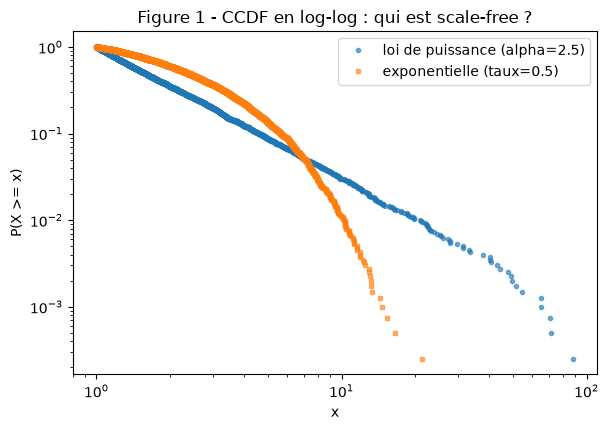

In [2]:
rng = random.Random(GRAINE)
ech_pl  = sf.sample_powerlaw(2.5, 1.0, 4000, rng)   # vraie loi de puissance
ech_exp = sf.sample_exponential(0.5, 1.0, 4000, rng)  # echelle caracteristique 1/0.5

fig, ax = plt.subplots(figsize=(6.2, 4.4))
trace_ccdf(ax, ech_pl, "loi de puissance (alpha=2.5)", "o")
trace_ccdf(ax, ech_exp, "exponentielle (taux=0.5)", "s")
ax.set_xlabel("x"); ax.set_ylabel("P(X >= x)")
ax.set_title("Figure 1 - CCDF en log-log : qui est scale-free ?")
ax.legend(); fig.tight_layout(); plt.show()

On ne tranche pas a l'oeil. La méthode (Clauset, Shalizi & Newman) :

1. **Choisir le seuil de queue** $x_{\min}$ qui *minimise* la distance de
   Kolmogorov-Smirnov entre la queue et sa loi de puissance ajustee
   (`select_xmin`) — on ne suppose pas la loi de puissance, on cherche le segment
   ou elle colle le mieux.
2. **Estimer l'exposant** $\alpha$ par maximum de vraisemblance (`hill_alpha`).
3. **Mesurer l'ajustement** (distance KS) : grand KS => mauvais ajustement, la loi
   de puissance ne tient pas, quoi qu'en dise l'oeil.
4. **Comparer** loi de puissance vs exponentielle par rapport de log-vraisemblance
   $R$. La fonction `compare_powerlaw_exponential` enchaine tout : elle ne declare
   *scale-free* que si l'ajustement tient (KS faible) **et** que la loi de
   puissance bat l'exponentielle.

In [3]:
for nom, ech, disc in [("loi de puissance", ech_pl, False), ("exponentielle", ech_exp, False)]:
    xm = sf.select_xmin(ech, discrete=disc)
    d = sf.compare_powerlaw_exponential(ech, xmin=xm, discrete=disc)
    print(f"{nom:18s} xmin*={xm:6.2f}  alpha={d['alpha']:.2f}  "
          f"KS={d['ks']:.3f}  R={d['loglik_ratio']:+.0f}  ->  {d['verdict']}")

loi de puissance   xmin*=  1.00  alpha=2.52  KS=0.012  R=+1137  ->  scale-free (loi de puissance, ajustement correct)


exponentielle      xmin*=  6.96  alpha=5.56  KS=0.057  R=-2  ->  echelle caracteristique (exponentielle preferee)


La boite a outils retrouve la verite : l'exposant de la loi de puissance est
estime a ~2.5 (sa vraie valeur) avec un KS minuscule et un $R$ très positif —
**scale-free** ; pour l'exponentielle, l'ajustement reste passable mais
l'exponentielle **est preferee** a la loi de puissance ($R<0$) — **echelle
caractéristique**. C'est l'etalonnage : la méthode classe correctement des cas dont
on connait la reponse. On peut maintenant l'appliquer a des systèmes ou on ne la
connait pas.

## 3. Un système reellement scale-free : le branchement critique

Le banc d'essai canonique de la criticalite est le **processus de branchement**
(Galton-Watson) : une graine engendre un nombre aleatoire de descendants
(progeniture de moyenne $\mu$), qui en engendrent a leur tour. La **taille
d'avalanche** est le nombre total de noeuds.

- $\mu < 1$ (sous-critique) : les avalanches s'eteignent vite — **echelle
  caractéristique**.
- $\mu = 1$ (**critique**) : la théorie est exacte. La taille totale suit la loi de
  Borel $P(s) = s^{s-1} e^{-s}/s!$, dont la queue est $\sim s^{-3/2}$ : une **loi de
  puissance d'exposant $\tau = 3/2$**. Aucune echelle ne domine.
- $\mu > 1$ (sur-critique) : des avalanches geantes apparaissent.

C'est notre etalon de *vrai* scale-free, avec un exposant connu d'avance ($1.5$) :
le diagnostic doit le retrouver.

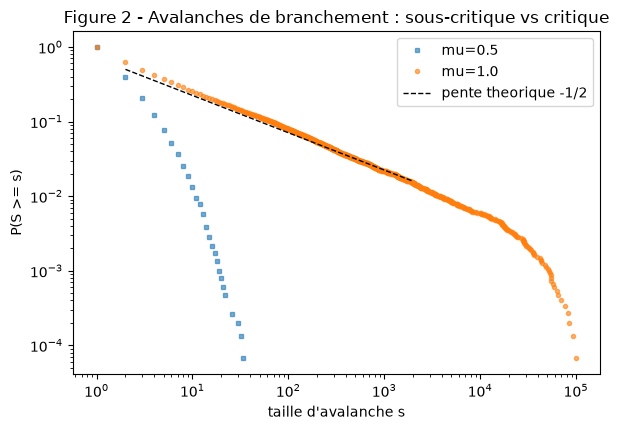

mu=0.5  xmin*=11  alpha=4.64  KS=0.168  ->  echelle caracteristique (ajustement loi de puissance insuffisant)


mu=1.0  xmin*=64  alpha=1.58  KS=0.017  ->  scale-free (loi de puissance, ajustement correct)


In [4]:
rng = random.Random(GRAINE + 1)
N_AVAL = 15000
# on compare les deux regimes nets : sous-critique (echelle caracteristique) et
# critique (scale-free). Le sur-critique produit des avalanches geantes qui debordent.
avalanches = {mu: sf.branching_avalanche_sizes(mu, N_AVAL, rng) for mu in (0.5, 1.0)}

fig, ax = plt.subplots(figsize=(6.2, 4.4))
for mu, marker in [(0.5, "s"), (1.0, "o")]:
    finis = [s for s in avalanches[mu] if s < 100000]
    trace_ccdf(ax, finis, f"mu={mu}", marker)
# pente theorique -(tau-1) = -1/2 en CCDF (cas critique)
xx = np.array([2, 2000]); ax.loglog(xx, 0.5 * (xx / 2.0) ** (-0.5), "k--", lw=1, label="pente theorique -1/2")
ax.set_xlabel("taille d'avalanche s"); ax.set_ylabel("P(S >= s)")
ax.set_title("Figure 2 - Avalanches de branchement : sous-critique vs critique")
ax.legend(); fig.tight_layout(); plt.show()

for mu in (0.5, 1.0):
    finis = [s for s in avalanches[mu] if s < 100000]
    xm = sf.select_xmin(finis, discrete=True)
    d = sf.compare_powerlaw_exponential(finis, xmin=xm, discrete=True)
    a = f"{d['alpha']:.2f}" if d['alpha'] else "NA"
    print(f"mu={mu}  xmin*={xm}  alpha={a}  KS={d['ks']:.3f}  ->  {d['verdict']}")

Le verdict suit la théorie. Le cas critique $\mu = 1$ est declare **scale-free**, et
surtout l'exposant estime tombe sur $\alpha \approx 1.5$ — exactement le $\tau = 3/2$
de la loi de Borel : ce n'est pas seulement le verdict qui colle, c'est la *valeur*
predite d'avance qui est retrouvee. La courbe critique longe la droite de pente
$-1/2$ sur plusieurs decades. Le cas sous-critique $\mu = 0.5$, lui, **echoue** au
test de loi de puissance (KS trop grand) : ses avalanches s'eteignent vite, ce qui
impose une **echelle caractéristique**.

C'est le bon reflexe : ne pas se fier au seul mot *scale-free* mais a l'**exposant**.
Pres de la criticalite, une loi de puissance a coupure très lointaine peut tromper
le verdict localement ; seul $\mu = 1$ produit le $\tau = 3/2$ théorique, signe que
la signature est reelle et non un artefact d'ajustement (l'**Exercice 1** fait
explorer cette fenêtre). Le scale-free n'est donc **pas** un regime generique : il
vit sur un point précis. C'est tout l'argument de Jansma & Hoel — une organisation
multi-echelle nette est un accident finement règle, pas la règle.

## 4. Retour au tri auto-organise : a queue lourde, mais *pas* scale-free

Reprenons le système vedette de la serie : le **tri auto-organise** vue-cellule
d'[ICT-2](ICT-02-SelfSortingMorphogenesis-Python.ipynb) (tableaux chimeriques alternant
les algotypes `bubble`/`insertion`). On en extrait une signature naturelle : le
**deplacement net** de chaque cellule, $\lvert {\rm position\ initiale} - {\rm position\
finale} \rvert$, sur de nombreuses permutations aleatoires. Certaines cellules voyagent
loin, d'autres a peine : la distribution a une queue. Est-elle scale-free ?

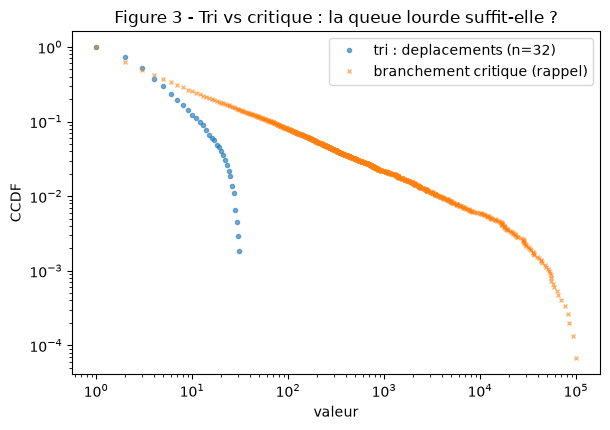

deplacements du tri : xmin*=11  alpha=3.10  KS=0.112  R=-34  ->  echelle caracteristique (ajustement loi de puissance insuffisant)
deplacement maximal observe = 31  (borne par n-1 = 31)


In [5]:
rng = random.Random(GRAINE + 2)
dep = deplacements_tri(n=32, n_runs=140, seed0=0)

fig, ax = plt.subplots(figsize=(6.2, 4.4))
trace_ccdf(ax, dep, "tri : deplacements (n=32)", "o")
crit = [s for s in avalanches[1.0] if s < 100000]
trace_ccdf(ax, crit, "branchement critique (rappel)", "x")
ax.set_xlabel("valeur"); ax.set_ylabel("CCDF")
ax.set_title("Figure 3 - Tri vs critique : la queue lourde suffit-elle ?")
ax.legend(); fig.tight_layout(); plt.show()

xm = sf.select_xmin(dep, discrete=True)
d = sf.compare_powerlaw_exponential(dep, xmin=xm, discrete=True)
print(f"deplacements du tri : xmin*={xm}  alpha={d['alpha']:.2f}  "
      f"KS={d['ks']:.3f}  R={d['loglik_ratio']:+.0f}  ->  {d['verdict']}")
print(f"deplacement maximal observe = {max(dep)}  (borne par n-1 = {32-1})")

Le piege se referme — et le diagnostic le detecte. A l'oeil, la courbe du tri a bien
une allure de queue lourde, comparable a celle de l'avalanche critique sur la
gauche. Mais l'ajustement par loi de puissance **echoue** (KS au-dessus du seuil),
et la cause saute aux yeux dans la dernière ligne : le deplacement est **borne par
la taille du système** ($n-1$). Cette borne *est* l'echelle caractéristique. Un
système scale-free n'a, par definition, aucune echelle privilegiee ; ici il y en a
une, imposee par la taille.

Lecon de fond pour ICT : des **règles locales a une seule echelle** (chaque cellule
ne voit que ses voisins immediats, cf. ICT-2/ICT-4) trient efficacement et reparent,
mais ne s'auto-organisent **pas** vers la criticalite. Le scale-free demande un
reglage particulier (etre poise au bord d'une transition) que ces règles minimales
ne possedent pas. Mesurer la signature plutot que la supposer evite de prendre une
queue lourde banale pour une organisation multi-echelle profonde.

## 5. Auto-similarite et effondrement d'echelle (le cote fractal)

Une signature scale-free est **auto-similaire** : zoomer ne change pas la forme.
Une signature a echelle caractéristique, au contraire, possede *une* echelle qui,
une fois retiree, fait coincider les distributions. Le test fractal canonique est
l'**effondrement d'echelle** (data collapse) : on fait varier la taille du système
et on renormalise l'axe des x.

Pour le tri, l'echelle candidate est la taille $n$. Tracons les CCDF des
deplacements pour $n \in \{20, 30, 40\}$, brutes puis renormalisees par $x/n$.

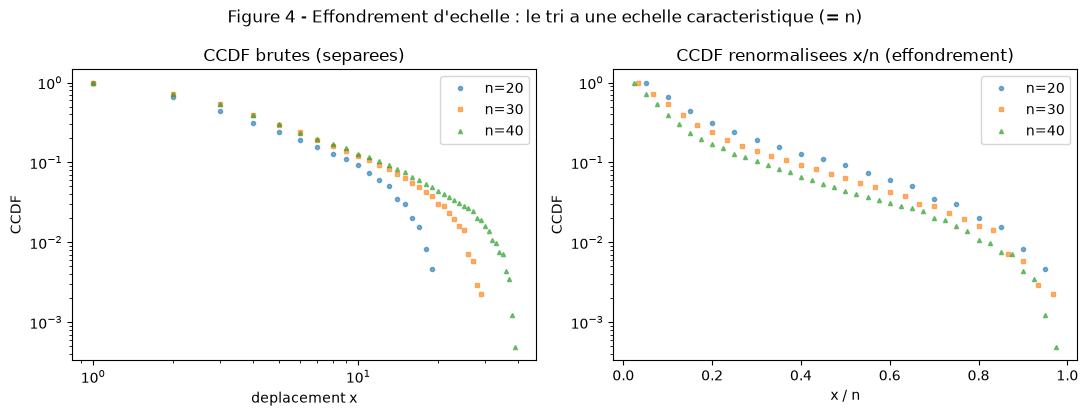

In [6]:
rng = random.Random(GRAINE + 3)
deps = {n: deplacements_tri(n=n, n_runs=120, seed0=1000 + n) for n in (20, 30, 40)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for n, mk in [(20, "o"), (30, "s"), (40, "^")]:
    trace_ccdf(axes[0], deps[n], f"n={n}", mk)
    xs, ps = sf.rescaled_ccdf(deps[n], scale=n)        # x -> x/n
    axes[1].semilogy(xs, ps, marker=mk, ls="none", ms=3, alpha=0.6, label=f"n={n}")
axes[0].set_title("CCDF brutes (separees)"); axes[0].set_xlabel("deplacement x")
axes[0].set_ylabel("CCDF"); axes[0].legend()
axes[1].set_title("CCDF renormalisees x/n (effondrement)"); axes[1].set_xlabel("x / n")
axes[1].set_ylabel("CCDF"); axes[1].legend()
fig.suptitle("Figure 4 - Effondrement d'echelle : le tri a une echelle caracteristique (= n)")
fig.tight_layout(); plt.show()

Les CCDF brutes se separent (a gauche) : plus le tableau est grand, plus les
deplacements peuvent etre grands. Renormalisees par $x/n$ (a droite), elles **se
superposent** : il existait une seule echelle, la taille $n$, et l'avoir retiree
fait coincider les courbes. C'est la signature même d'une **echelle
caractéristique** — l'oppose du scale-free, qui ne se laisse reduire par aucune
renormalisation unique (l'avalanche critique de la Figure 2 garde la même forme a
toutes les echelles, sa coupure ne faisant que reculer avec la taille du système).

## 6. Garde-fou avance : le test d'adequation par bootstrap

Le KS et le rapport $R$ comparent deux modèles ; on peut aller plus loin et demander
si la loi de puissance ajustee est, *a elle seule*, un modèle credible. `scale_free`
fournit pour cela un test d'adequation par bootstrap (`gof_pvalue`, facon Clauset et
al.) : on simule de nombreux echantillons issus de la loi de puissance ajustee et on
mesure la fraction dont l'ecart KS est *au moins aussi grand* que celui observe. Une
**p-valeur elevee** signifie que l'ecart observe est typique d'une vraie loi de
puissance (on ne la rejette pas) ; une **p-valeur proche de 0** la rejette.

Appliquons-le aux deux cas tranches du notebook : le branchement **critique**
(qu'on attend *confirme*) et les **deplacements du tri** (qu'on attend *rejetes*).

In [7]:
boot = random.Random(GRAINE + 4)

# (a) branchement critique : on attend une confirmation (p-valeur elevee)
crit = [s for s in avalanches[1.0] if s < 100000]
xm_c = sf.select_xmin(crit, discrete=True)
d_c = sf.compare_powerlaw_exponential(crit, xmin=xm_c, discrete=True, rng=boot, gof_boot=200)
print(f"branchement critique  : alpha={d_c['alpha']:.2f}  KS={d_c['ks']:.3f}  "
      f"p-GoF={d_c['gof_pvalue']}  ->  {d_c['verdict']}")

# (b) deplacements du tri (calcules en section 4) : on attend un rejet (p-valeur ~ 0)
xm_d = sf.select_xmin(dep, discrete=True)
d_d = sf.compare_powerlaw_exponential(dep, xmin=xm_d, discrete=True, rng=boot, gof_boot=200)
print(f"deplacements du tri   : alpha={d_d['alpha']:.2f}  KS={d_d['ks']:.3f}  "
      f"p-GoF={d_d['gof_pvalue']}  ->  {d_d['verdict']}")

branchement critique  : alpha=1.58  KS=0.017  p-GoF=0.625  ->  scale-free (loi de puissance, ajustement correct)
deplacements du tri   : alpha=3.10  KS=0.112  p-GoF=0.0  ->  echelle caracteristique (ajustement loi de puissance insuffisant)


Le test tranche dans le bon sens : il **confirme** le branchement critique
(p-valeur elevee — l'ecart KS est celui d'une vraie loi de puissance) et **rejette**
les deplacements du tri (p-valeur effondree). C'est le troisieme angle, concordant
avec le KS et le rapport $R$ : les trois outils designent le même coupable.

Une mise en garde demeure, a enseigner : la p-valeur bootstrap est **sensible au
choix de $x_{\min}$**. Applique a un segment trop court ou trop bas (mauvais
$x_{\min}$), le test sur-rejette, même un vrai scale-free, car la loi de puissance
n'est exacte qu'asymptotiquement. D'ou la règle de la serie : choisir $x_{\min}$ par
minimisation du KS *d'abord*, puis lire le bootstrap comme un troisieme avis — jamais
comme un juge unique.

## 7. Exercices

Trois exercices pour s'approprier la detection scale-free. Les solutions ne sont
pas fournies (cellules a completer) ; le notebook s'execute de bout en bout même
laissees en l'etat.

### Exercice 1 — Localiser la criticalite

Le branchement est scale-free **exactement** a $\mu = 1$. Balayez $\mu$ de $0.85$ a
$1.15$ par pas de $0.05$ ; pour chaque valeur, generez un echantillon d'avalanches,
appliquez la chaîne `select_xmin` + `compare_powerlaw_exponential`, et reperez ou le
verdict bascule vers *scale-free* et ou l'exposant estime s'approche de $1.5$.

```
# Indice : reutilisez sf.branching_avalanche_sizes(mu, N, rng) et filtrez s < 100000.
# Indice : stockez (mu, verdict, alpha, KS) puis affichez le tableau.
# Étape 1 : construire la liste des mu.
# Étape 2 : pour chaque mu, diagnostiquer.
# Étape 3 : conclure sur la fenêtre de mu compatible avec le scale-free.
```

In [8]:
# Exercice 1 : a completer.
# resultat attendu : un tableau (mu, verdict, alpha, KS) montrant la bascule autour de mu=1.
resultat_ex1 = None  # TODO etudiant
print("Exercice 1 a completer")

Exercice 1 a completer


### Exercice 2 — Classer un echantillon mystere

On vous donne un echantillon `mystere` (genere ci-dessous sans vous dire son
origine). Appliquez la **chaîne complete** de diagnostic et concluez : scale-free ou
echelle caractéristique ? Justifiez avec l'exposant, le KS, et le rapport $R$.

```
# Indice : ne tranchez pas sur le trace log-log seul (c'est tout l'enjeu du notebook).
# Indice : sf.select_xmin puis sf.compare_powerlaw_exponential.
# Étape 1 : tracer la CCDF (pour l'intuition).
# Étape 2 : diagnostiquer quantitativement.
# Étape 3 : ecrire le verdict argumente.
```

In [9]:
# Echantillon mystere (ne regardez pas comment il est fait avant d'avoir conclu) :
from statistics import NormalDist

_rng_mystere = random.Random(2024)
_normale_mystere = NormalDist()
mystere = [
    max(1, round(np.exp(0.3 + 0.9 * _normale_mystere.inv_cdf(_rng_mystere.random()))))
    for _ in range(8000)
]
mystere = [s for s in mystere if s < 100000]

# Exercice 2 : a completer.
resultat_ex2 = None  # TODO etudiant
print("Exercice 2 a completer -", len(mystere), "observations a classer")

Exercice 2 a completer - 8000 observations a classer


### Exercice 3 — Effondrement d'echelle de votre cru

Reproduisez l'idee de la Figure 4 sur une autre signature du tri : par exemple le
**nombre total d'echanges** pour trier (au lieu du deplacement). Variez $n$,
verifiez si la distribution possede une echelle caractéristique en cherchant la
renormalisation qui fait coincider les courbes. Si oui, quelle puissance de $n$ ?

```
# Indice : arr.probe.swaps donne le nombre d'echanges d'une exécution.
# Indice : pour un tri, le nombre d'echanges croit comme une puissance de n -- testez x / n**k.
# Étape 1 : collecter les nombres d'echanges pour plusieurs n.
# Étape 2 : tracer brut puis renormalise.
# Étape 3 : identifier l'echelle (la puissance k) qui fait l'effondrement.
```

In [10]:
# Exercice 3 : a completer.
resultat_ex3 = None  # TODO etudiant
print("Exercice 3 a completer")

Exercice 3 a completer


## 8. Gates de dégénérescence — le diagnostic peut-il échouer ?

Le principe d'ICT-01 s'applique à la chaîne de diagnostic elle-même : **un témoin qui ne peut pas échouer n'est pas un témoin**. L'instrument central ici est la chaîne `select_xmin` -> ajustement (KS) -> comparaison de modèles (R) du module `ict.scale_free`, avec ses échantillons de référence. Un détecteur scale-free complaisant dirait « scale-free » de toute queue lourde — c'est exactement le piège du log-log de la section 2. Les quatre portes ci-dessous vérifient qu'il rend des réponses *différentes* selon l'échantillon présenté, exposant retrouvé à l'appui. Chaque porte imprime son propre verdict ; il n'y a **pas de verdict agrégé**.

| Porte | Question posée à l'instrument | Réponse d'un automate complaisant |
|---|---|---|
| **G1 — Témoin positif** | Une vraie loi de puissance (alpha = 2,5) et le branchement critique (tau = 3/2) sont-ils détectés scale-free, avec l'**exposant retrouvé** (± 0,25 / ± 0,30) ? | « scale-free » partout, exposant fantôme |
| **G2 — Négatif naïf** | Une exponentielle est-elle **rejetée** (échelle caractéristique), même dans la région où une loi de puissance s'ajuste ? | « scale-free » dès que le log-log paraît droit |
| **G3 — Négatif calibré** | L'instrument **discrimine**-t-il : sous-critique (mu = 0,5) rejeté contre critique (mu = 1,0) retenu, et queue lourde *bornée* du tri (section 4) rejetée ? | confondre queue lourde et scale-free |
| **G4 — Référence analytique** | Les CCDF collent-elles à leurs **formes fermées** (exp(-taux(x-xmin)), x^-(alpha-1)) et l'estimateur suit-il l'exposant injecté (2,0 / 2,5 / 3,0) ? | un exposant « plausible » constant, quel que soit l'entrée |

In [11]:
# --- Gates de degenerescence : le diagnostic doit pouvoir echouer ---
# Principe ICT-01 : un temoin qui ne peut pas echouer n'est pas un temoin.
# Chaque porte imprime son verdict ; aucun agregat, aucun assert bloquant.
# Reutilise les echantillons des sections 3 (avalanches) et 4 (dep) ;
# les references neuves utilisent des graines propres (GRAINE + 10/20/40).

print("G1 -- temoin positif : l'exposant est-il retrouve, pas seulement le verdict ?")
rng_g1 = random.Random(GRAINE + 10)
vrai_pl = sf.sample_powerlaw(2.5, 1.0, 4000, rng_g1)             # reference neuve
xm_pl = sf.select_xmin(vrai_pl)
d_pl = sf.compare_powerlaw_exponential(vrai_pl, xmin=xm_pl)
c1a = (d_pl["verdict"].startswith("scale-free")
       and abs(d_pl["alpha"] - 2.5) <= 0.25)
crit = [s for s in avalanches[1.0] if s < 100000]                # section 3, critique
xm_c = sf.select_xmin(crit, discrete=True)
d_c = sf.compare_powerlaw_exponential(crit, xmin=xm_c, discrete=True)
c1b = (d_c["verdict"].startswith("scale-free")
       and abs(d_c["alpha"] - 1.5) <= 0.30)                       # tau = 3/2 (Borel)
print(f"  loi de puissance alpha=2.5 : alpha={d_pl['alpha']:.2f} (attendu 2.50+-0.25), KS={d_pl['ks']:.3f}")
print(f"  branchement critique tau=3/2 : alpha={d_c['alpha']:.2f} (attendu 1.50+-0.30), KS={d_c['ks']:.3f}")
print(f"G1 : {'PASSED' if (c1a and c1b) else 'FAILED'}")

print("\nG2 -- negatif naif : l'exponentielle est-elle rejetee ?")
rng_g2 = random.Random(GRAINE + 20)
vrai_exp = sf.sample_exponential(0.5, 1.0, 4000, rng_g2)         # reference neuve
xm_e = sf.select_xmin(vrai_exp)
d_e = sf.compare_powerlaw_exponential(vrai_exp, xmin=xm_e)
c2 = d_e["verdict"].startswith("echelle caracteristique")
print(f"  alpha={d_e['alpha']:.2f}, KS={d_e['ks']:.3f} (une loi de puissance s'ajuste sur cette region), "
      f"R={d_e['loglik_ratio']:+.0f}")
print(f"  verdict : {d_e['verdict']}")
print(f"G2 : {'PASSED' if c2 else 'FAILED'}")

print("\nG3 -- negatif calibre : queue lourde n'est pas scale-free")
sous = [s for s in avalanches[0.5] if s < 100000]                # section 3, sous-critique
xm_s = sf.select_xmin(sous, discrete=True)
d_s = sf.compare_powerlaw_exponential(sous, xmin=xm_s, discrete=True)
c3a = not d_s["verdict"].startswith("scale-free")                # mu=0.5 rejete...
xm_d = sf.select_xmin(dep, discrete=True)                        # section 4, tri
d_d = sf.compare_powerlaw_exponential(dep, xmin=xm_d, discrete=True)
c3b = not d_d["verdict"].startswith("scale-free")                # ...et le tri aussi
print(f"  sous-critique mu=0.5 : alpha={d_s['alpha']:.2f}, KS={d_s['ks']:.3f}, R={d_s['loglik_ratio']:+.0f}")
print(f"  tri (borne par n-1=31) : alpha={d_d['alpha']:.2f}, KS={d_d['ks']:.3f}, R={d_d['loglik_ratio']:+.0f}")
print("  (contre mu=1.0 retenu en G1 : le meme instrument separe les regimes)")
print(f"G3 : {'PASSED' if (c3a and c3b) else 'FAILED'}")

print("\nG4 -- reference analytique : formes fermees et suivi d'exposant")
rng_g4 = random.Random(GRAINE + 40)
n_g4 = 20000
ech_e = sf.sample_exponential(0.5, 1.0, n_g4, rng_g4)
err_e = max(abs(sum(1 for v in ech_e if v >= x) / n_g4 - np.exp(-0.5 * (x - 1.0)))
            for x in (2.0, 4.0, 8.0, 16.0))                      # CCDF = exp(-taux*(x-xmin))
ech_p = sf.sample_powerlaw(3.0, 1.0, n_g4, rng_g4)
err_p = max(abs(sum(1 for v in ech_p if v >= x) / n_g4 - x ** -2.0)
            for x in (2.0, 4.0, 8.0))                            # CCDF = x^-(alpha-1), alpha=3
ecarts = [abs(sf.hill_alpha(sf.sample_powerlaw(a, 1.0, 4000, rng_g4), 1.0) - a)
          for a in (2.0, 2.5, 3.0)]                              # l'estimateur suit-il a ?
c4 = (err_e <= 0.02 and err_p <= 0.02 and max(ecarts) <= 0.25)
print(f"  CCDF exponentielle vs exp(-0.5(x-1)) : ecart max {err_e:.4f} (<= 0.02)")
print(f"  CCDF puissance vs x^-2 : ecart max {err_p:.4f} (<= 0.02)")
print(f"  exposant injecte 2.0/2.5/3.0 -> ecarts {[round(e, 3) for e in ecarts]} (<= 0.25)")
print(f"G4 : {'PASSED' if c4 else 'FAILED'}")

G1 -- temoin positif : l'exposant est-il retrouve, pas seulement le verdict ?


  loi de puissance alpha=2.5 : alpha=2.53 (attendu 2.50+-0.25), KS=0.008
  branchement critique tau=3/2 : alpha=1.58 (attendu 1.50+-0.30), KS=0.017
G1 : PASSED

G2 -- negatif naif : l'exponentielle est-elle rejetee ?


  alpha=5.24, KS=0.043 (une loi de puissance s'ajuste sur cette region), R=-4
  verdict : echelle caracteristique (exponentielle preferee)
G2 : PASSED

G3 -- negatif calibre : queue lourde n'est pas scale-free
  sous-critique mu=0.5 : alpha=4.64, KS=0.168, R=+0
  tri (borne par n-1=31) : alpha=3.10, KS=0.112, R=-34
  (contre mu=1.0 retenu en G1 : le meme instrument separe les regimes)
G3 : PASSED

G4 -- reference analytique : formes fermees et suivi d'exposant
  CCDF exponentielle vs exp(-0.5(x-1)) : ecart max 0.0014 (<= 0.02)
  CCDF puissance vs x^-2 : ecart max 0.0071 (<= 0.02)
  exposant injecte 2.0/2.5/3.0 -> ecarts [0.001, 0.039, 0.07] (<= 0.25)
G4 : PASSED


### Lecture du résultat

Les quatre portes sont **PASSED** sur cette exécution — chacune en rendant des réponses *différentes* selon l'échantillon présenté :

- **G1** : l'exposant est *retrouvé*, pas seulement le verdict — **2,53** pour un alpha = 2,5 injecté, **1,58** pour la loi de Borel du branchement critique (tau = 3/2), l'écart attendu pour 15 000 avalanches. Un automate qui répondrait « scale-free » avec un exposant fantôme ne passe pas cette porte.
- **G2** : le piège est bien réel — `select_xmin` trouve une région où une loi de puissance *s'ajuste* à l'exponentielle (KS = 0,043) ; c'est la comparaison de vraisemblance (R = -4) qui tranche pour l'échelle caractéristique. Sans le deuxième étage, le diagnostic serait dégénéré.
- **G3** : le même instrument sépare les régimes — mu = 1,0 retenu (G1), mu = 0,5 rejeté (KS = 0,168) — et rejette la queue lourde du tri *deux fois* : par la vraisemblance (R = -34) et par l'adéquation (KS = 0,112), en accord avec le bootstrap de la section 6 (p = 0). Queue lourde n'est pas scale-free.
- **G4** : les CCDF collent à leurs formes fermées (écarts ≤ 0,008) et l'estimateur suit l'exposant injecté (écarts ≤ 0,07 sur alpha = 2,0 / 2,5 / 3,0) : la chaîne mesure une quantité, elle ne raconte pas une histoire.

L'échantillon `mystere` de l'exercice 2 reste volontairement hors de ces portes : le classer ici fermerait l'exercice. L'automate complaisant — celui qui dirait « scale-free » de toute queue lourde — aurait rendu le même verdict aux portes 2 et 3. Ce n'est pas ce qui se passe : le diagnostic échoue quand il doit échouer. **C'est un témoin.**

## Conclusion & ponts

- **Detecter une signature scale-free est une competence, pas un coup d'oeil.** Le
  trace log-log trompe : on a vu une queue lourde banale (les deplacements du tri,
  bornes par la taille) ressembler a une avalanche critique. Seule la chaîne
  *choix de $x_{\min}$ par minimisation du KS -> exposant par maximum de
  vraisemblance -> qualite d'ajustement -> comparaison de modèles* tranche
  honnetement.
- **Le scale-free est rare et règle.** Notre seul vrai cas sans echelle est le
  branchement **a la criticalite** ($\mu = 1$, exposant $3/2$ retrouve). De part et
  d'autre, une echelle caractéristique reapparait. C'est l'argument de Jansma &
  Hoel : une organisation multi-echelle nette est particuliere, pas generique.
- **Les règles locales mono-echelle du tri ne s'auto-organisent pas vers la
  criticalite.** Elles trient, reparent (ICT-2/ICT-4), mais leur signature a une
  echelle caractéristique : la taille du système, revelee par l'effondrement
  d'echelle.

- **Gates de dégénérescence (§8)** : les quatre portes PASSED — exposants retrouvés (2,53 pour alpha = 2,5 ; 1,58 pour tau = 3/2), exponentielle rejetée par la vraisemblance malgré un ajustement décent, sous-critique et queue lourde du tri rejetés, formes fermées vérifiées. Le diagnostic scale-free est un témoin qui peut échouer, pas un automate.

**Ponts dans la serie ICT :**

- [ICT-5](ICT-05-CausalEmergence-Python.ipynb) / [ICT-6](ICT-06-SortingToTPM-CausalEmergence-Python.ipynb) :
  l'emergence causale y est, elle aussi, *discriminante* — un macro-niveau n'est
  pertinent que s'il bat le micro, exactement comme une signature n'est scale-free
  que si elle survit au diagnostic. Même discipline anti-complaisance.
- **Criticalite auto-organisee** (Bak, Tang & Wiesenfeld 1987) : certains systèmes
  *se conduisent* vers la criticalite sans reglage externe. Un prolongement
  naturel : un modèle de tri/morphogenese qui s'auto-organiserait vers le scale-free
  produirait-il une emergence causale plus forte (au sens d'ICT-5/6) ?
- [ICT-0](ICT-0-Framing.md) : ce notebook clot la question des signatures
  multi-echelles posee dans le cadrage.

**References :**

- A. Clauset, C. R. Shalizi, M. E. J. Newman, *Power-law distributions in empirical
  data*, SIAM Review 51(4), 2009 — méthode de diagnostic suivie ici.
- A. Jansma, E. Hoel, *Engineering Emergence*, 2025 — emergence multi-echelle,
  rarete des organisations causales nettes.
- P. Bak, C. Tang, K. Wiesenfeld, *Self-organized criticality*, Phys. Rev. Lett.
  59, 1987 — criticalite et signatures sans echelle.
- T. E. Harris, *The Theory of Branching Processes*, 1963 — loi de Borel, exposant
  $3/2$ a la criticalite.